In [1]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
import matplotlib.pyplot as plt
import sys
sys.path.append('/suphys/aani0116/Work/minicluster_model_new/my_modules/')
from scipy.stats import uniform_direction
from reverse_orbit import *
from mc_declare import *
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
from N_calculator import *
from scipy.integrate import quad
from hmf import get_mass
from times import dynamical_time
from mass_loss_new import *
from generate_particles import *
from radius_and_energy import *
from sklearn.decomposition import PCA
from mc_xv import generate_xv_at,generate_xv

kappa=3.54
beta=3.47


In [2]:
simulation_time=10

final_pos=np.array([8.0,0.0,0.0,1.0,1.0,220.0])
mc_center=reverse_orbit(ic=final_pos,pot= pot_mw,time=simulation_time,timestart=0,show_start=0)
mc_start=mc_center.copy()
mc_end=final_pos.copy()
mcp_xv,mcp_mass=np.empty((0, 6)),np.array([]) 

In [3]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
Nbody_total=1e4
pmass=mc.mass/Nbody_total
print('mass and radius:',mc.mass,mc.radius,pmass)



mass and radius: 3.8881314532980394e-14 2.724456521434293e-12 3.8881314532980394e-18


In [4]:
orb=agama.orbit(ic=mc_center, potential=pot_mw, time=simulation_time, timestart=0, dtype=object, accuracy=1e-10, verbose=False)

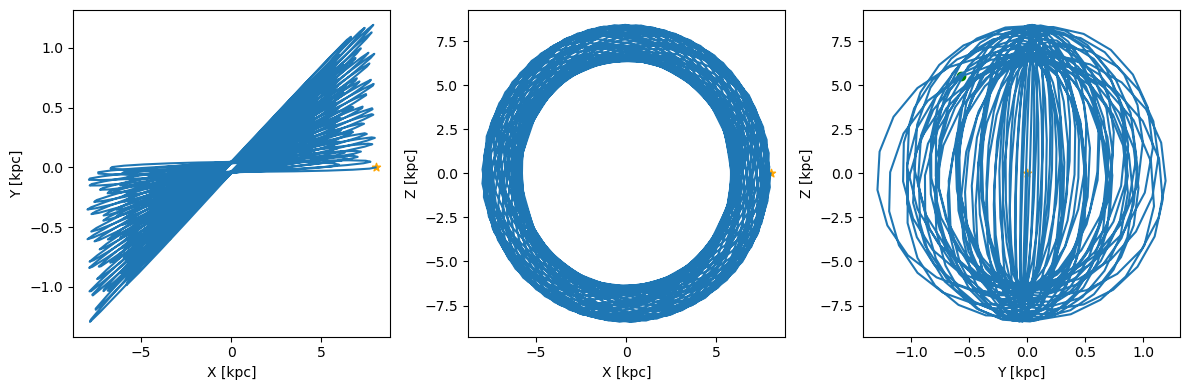

In [5]:
t=np.linspace(0,simulation_time,1000)
o=orb(t)
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1])
ax[0].scatter(final_pos[0],final_pos[1],c='orange',marker='*')
ax[0].scatter(mc_center[0],mc_center[1],c='green')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2])
ax[1].scatter(final_pos[0],final_pos[2],c='orange',marker='*')
ax[1].scatter(mc_center[0],mc_center[2],c='green')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2])
ax[2].scatter(final_pos[1],final_pos[2],c='orange',marker='*')
ax[2].scatter(mc_center[1],mc_center[2],c='green')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [6]:
def stellar_energy(N,M,R,v,its_sum):
    #b = np.sqrt(np.random.uniform(0, (1e-3)**2, N))
    b=np.random.uniform(1000*R, (1e-4), N)
    E=((4*0.33*agama.G*agama.G*M*0.27*R*R)/((b**4)*(v**2)))
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:
        return E_sum
    else:
        return E_rms_sum

In [7]:
def N_encounter_new(t,xv, b_max=1e-3): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)

In [8]:
tupd = 1e-2
time_i = 0


mc_mass=mc.mass
mc_rvir=mc.radius
print('simulation time',simulation_time)


simulation time 10


In [9]:
#random stuff for plotting
mc_array=[mc_center]
mc_time=[]
pnum_array=[]
mass_array,radius_array=[],[]
Ef_array,Ei_array,E2_array,E3_array,N_encounter_with_star_array =[],[],[],[],[]
color=[0]
SD=[]
SD_r=[]
SD_t=[]
SD_axis=[]
R_vector=[]
mean_axis_length=[]

In [11]:
color_index=0
SD_count=0

while time_i < simulation_time-0.5*tupd:

    mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)
    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center)
    N_encounter_with_star_array.append(N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
    delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
    
    

    Eb=binding_energy(mc_mass,mc_rvir)
    Ei=total_energy(Eb)

    delEbyE=abs(delE/Eb)
    mass_loss=mc_mass*get_dm_frac(delEbyE)

    Ef=Ei+(1-get_fej(delEbyE))*delE-get_fub(delEbyE)*Ei
    
    Ef_array.append(Ef)
    Ei_array.append(Ei)
    E2_array.append((1-get_fej(delEbyE))*delE)
    E3_array.append(get_fub(delEbyE)*Ei)
    
    mc_mass_old=mc_mass
    mc_mass=mc_mass-mass_loss
    mc_rvir=((kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef) if Ef<0 else 0

    mass_array.append(mc_mass)
    radius_array.append(mc_rvir)
    mc_array.append(mc_orbit_center)
    mc_time.append(mc_time_center[-1])

    #r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass_old)
    r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass)


    pnum=round(mass_loss*Nbody_total/mc.mass)
    pnum_array.append(pnum)
    if mc_rvir==0:
        print('dead')
        pnum=round(mc_mass_old*Nbody_total/mc.mass)
        mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass_old,r_tidal,pnum,pmass)
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        mcp_xv_temp+=mc_center
        mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
        mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=simulation_time-time_i, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=1)[:, 1])        
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)
        SD.append(pca.explained_variance_**0.5)
        alive=0
        break    
        
    if mcp_xv.size>0:
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
    
    mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
    mcp_xv_temp+=mc_orbit_center[-1]  
    mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
    mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
    
    """if pnum>0 and color_index!=0:
        print('color_index:',color_index,'first')
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        color_index+=1
        print('time:',time_i,'pnum:',pnum,'mass:',mc_mass,'radius:',mc_rvir)
        fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
        ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.8,c=color,cmap='viridis')
        ax[0].scatter(mcp_xv_temp[:,0],mcp_xv_temp[:,1],s=2,c='orange') 
        ax[0].set_xlabel('X [kpc]')
        ax[0].set_ylabel('Y [kpc]')

        ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
        ax[1].scatter(mcp_xv_temp[:,0],mcp_xv_temp[:,2],s=2,c='orange')
        ax[1].set_xlabel('X [kpc]')
        ax[1].set_ylabel('Z [kpc]')

        ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
        ax[2].scatter(mcp_xv_temp[:,1],mcp_xv_temp[:,2],s=2,c='orange')
        ax[2].set_xlabel('Y [kpc]')
        ax[2].set_ylabel('Z [kpc]')
        ax[2].set
        plt.show()
        plt.tight_layout()    
    elif pnum>0 and color_index==0:
        print('color_index:',color_index,'second')
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)[1:]*color_index])
        color_index+=1
    plt.plot(mcp_xv[:,0], mcp_xv[:,1], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,0], mcp_xv_temp[:,1], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][0], mc_orbit_center[-1][1], 's', markersize=5, color='red')
    plt.show()
    plt.plot(mcp_xv[:,0], mcp_xv[:,2], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,0], mcp_xv_temp[:,2], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][0], mc_orbit_center[-1][2], 's', markersize=5, color='red')
    plt.show()
    plt.plot(mcp_xv[:,1], mcp_xv[:,2], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,1], mcp_xv_temp[:,2], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][1], mc_orbit_center[-1][2], 's', markersize=5, color='red')
    plt.show()
    """

    if mcp_xv.size>1 and SD_count%1==0 and time_i>0:
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)
        SD.append(pca.explained_variance_**0.5)
        SD_t.append(time_i) 

        #pos=np.std(pos, axis=0)
        mean_axis_length.append(np.std(mcp_xv[:,:3],axis=0))

    mc_center = mc_orbit_center[-1]
    time_i += tupd
    


    SD_count+=1
    print(time_i,pnum)
#color=np.array(color[1:])
"""fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.8,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')
plt.tight_layout()"""

0.01 0
0.02 0
0.03 0
0.04 0
0.05 0
0.060000000000000005 0
0.07 0
0.08 0
0.09 0
0.09999999999999999 0
0.10999999999999999 0
0.11999999999999998 0
0.12999999999999998 0
0.13999999999999999 0
0.15 0
0.16 0
0.17 0
0.18000000000000002 0
0.19000000000000003 0
0.20000000000000004 0
0.21000000000000005 0
0.22000000000000006 0
0.23000000000000007 0
0.24000000000000007 0
0.25000000000000006 0
0.26000000000000006 0
0.2700000000000001 0
0.2800000000000001 0
0.2900000000000001 0
0.3000000000000001 0
0.3100000000000001 0
0.3200000000000001 0
0.3300000000000001 0
0.34000000000000014 0
0.35000000000000014 0
0.36000000000000015 0
0.37000000000000016 0
0.38000000000000017 0
0.3900000000000002 0
0.4000000000000002 0
0.4100000000000002 0
0.4200000000000002 0
0.4300000000000002 0
0.4400000000000002 0
0.45000000000000023 0
0.46000000000000024 0
0.47000000000000025 0
0.48000000000000026 0
0.49000000000000027 0
0.5000000000000002 0
0.5100000000000002 0
0.5200000000000002 0
0.5300000000000002 0
0.5400000000000

/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_los

1.8200000000000014 0
1.8300000000000014 0
1.8400000000000014 0
1.8500000000000014 0
1.8600000000000014 0
1.8700000000000014 0
1.8800000000000014 0
1.8900000000000015 0
1.9000000000000015 0
1.9100000000000015 0
1.9200000000000015 0
1.9300000000000015 0
1.9400000000000015 0
1.9500000000000015 0
1.9600000000000015 0
1.9700000000000015 0
1.9800000000000015 0
1.9900000000000015 0
2.0000000000000013 0
2.010000000000001 0
2.020000000000001 0
2.0300000000000007 0
2.0400000000000005 0
2.0500000000000003 0
2.06 0
2.07 0
2.0799999999999996 0
2.0899999999999994 0
2.099999999999999 0
2.109999999999999 0
2.1199999999999988 0
2.1299999999999986 0
2.1399999999999983 0
2.149999999999998 0
2.159999999999998 0
2.1699999999999977 0
2.1799999999999975 0
2.1899999999999973 0
2.199999999999997 0
2.209999999999997 0
2.2199999999999966 0
2.2299999999999964 0
2.239999999999996 0
2.249999999999996 0
2.259999999999996 0
2.2699999999999956 0
2.2799999999999954 0
2.289999999999995 0
2.299999999999995 0
2.3099999999

/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_los

2.4499999999999917 0
2.4599999999999915 0
2.4699999999999913 0
2.479999999999991 0
2.489999999999991 0
2.4999999999999907 0
2.5099999999999905 0
2.5199999999999902 0
2.52999999999999 0
2.53999999999999 0
2.5499999999999896 0
2.5599999999999894 0
2.569999999999989 0
2.579999999999989 0
2.5899999999999888 0
2.5999999999999885 0
2.6099999999999883 0
2.619999999999988 0
2.629999999999988 0
2.6399999999999877 0
2.6499999999999875 0
2.6599999999999873 0
2.669999999999987 0
2.679999999999987 0
2.6899999999999866 0
2.6999999999999864 0
2.709999999999986 0
2.719999999999986 0
2.7299999999999858 0
2.7399999999999856 0
2.7499999999999853 0
2.759999999999985 0
2.769999999999985 0
2.7799999999999847 0
2.7899999999999845 0
2.7999999999999843 0
2.809999999999984 0
2.819999999999984 0
2.8299999999999836 0
2.8399999999999834 0
2.849999999999983 0
2.859999999999983 0
2.869999999999983 0
2.8799999999999826 0
2.8899999999999824 0
2.899999999999982 0
2.909999999999982 0
2.9199999999999817 0
2.9299999999999

...

4.489999999999949 0
4.4999999999999485 0
4.509999999999948 0
4.519999999999948 0
4.529999999999948 0
4.539999999999948 0
4.549999999999947 0
4.559999999999947 0
4.569999999999947 0
4.579999999999947 0
4.589999999999947 0
4.599999999999946 0
4.609999999999946 0
4.619999999999946 0
4.629999999999946 0
4.6399999999999455 0
4.649999999999945 0
4.659999999999945 0
4.669999999999945 0
4.679999999999945 0
4.689999999999944 0
4.699999999999944 0
4.709999999999944 0
4.719999999999944 0
4.729999999999944 0
4.739999999999943 0
4.749999999999943 0
4.759999999999943 0
4.769999999999943 0
4.7799999999999425 0
4.789999999999942 0
4.799999999999942 0
4.809999999999942 0
4.819999999999942 0
4.8299999999999415 0
4.839999999999941 0
4.849999999999941 0
4.859999999999941 0
4.869999999999941 0
4.87999999999994 0
4.88999999999994 0
4.89999999999994 0
4.90999999999994 0
4.9199999999999395 0
4.929999999999939 0
4.939999999999939 0
4.949999999999939 0
4.959999999999939 0
4.9699999999999385 0
4.979999999999938 

/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_los

5.199999999999934 0
5.209999999999933 0
5.219999999999933 0
5.229999999999933 0
5.239999999999933 0
5.2499999999999325 0
5.259999999999932 0
5.269999999999932 0
dead


10000 orbits complete (403.1 orbits/s)                  


"fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)\nax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.8,c=color,cmap='viridis')\nax[0].set_xlabel('X [kpc]')\nax[0].set_ylabel('Y [kpc]')\n\nax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')\nax[1].set_xlabel('X [kpc]')\nax[1].set_ylabel('Z [kpc]')\n\nax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')\nax[2].set_xlabel('Y [kpc]')\nax[2].set_ylabel('Z [kpc]')\nplt.tight_layout()"

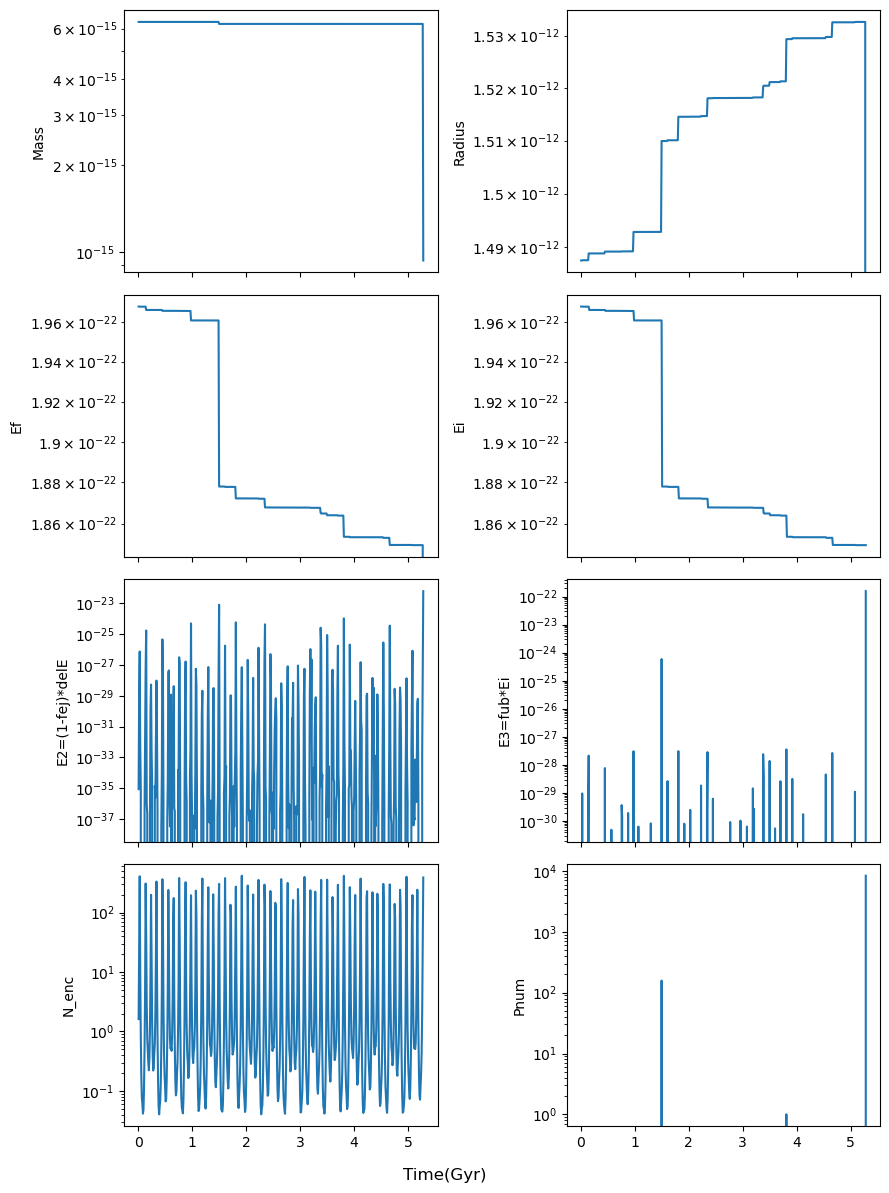

In [12]:
fig,ax=plt.subplots(4,2,figsize=(9,12),sharex=1)
ax[0,0].plot(mc_time,np.array(mass_array))
ax[0,0].set_ylabel('Mass')
ax[0,0].set_yscale('log')

ax[0,1].plot(mc_time,np.array(radius_array))
ax[0,1].set_ylabel('Radius')
ax[0,1].set_yscale('log')

ax[1,0].plot(mc_time,-np.array(Ef_array))
ax[1,0].set_ylabel('Ef')
ax[1,0].set_yscale('log')

ax[1,1].plot(mc_time,-np.array(Ei_array))
ax[1,1].set_ylabel('Ei')
ax[1,1].set_yscale('log')

ax[2,0].plot(mc_time,np.array(E2_array))
ax[2,0].set_ylabel('E2=(1-fej)*delE')
ax[2,0].set_yscale('log')

ax[2,1].plot(mc_time,-np.array(E3_array))
ax[2,1].set_ylabel('E3=fub*Ei')
ax[2,1].set_yscale('log')

ax[3,0].plot(mc_time,N_encounter_with_star_array)
ax[3,0].set_ylabel('N_enc')
ax[3,0].set_yscale('log')

ax[3,1].plot(mc_time,pnum_array)
ax[3,1].set_ylabel('Pnum')
ax[3,1].set_yscale('log')

fig.supxlabel('Time(Gyr)')

plt.tight_layout()

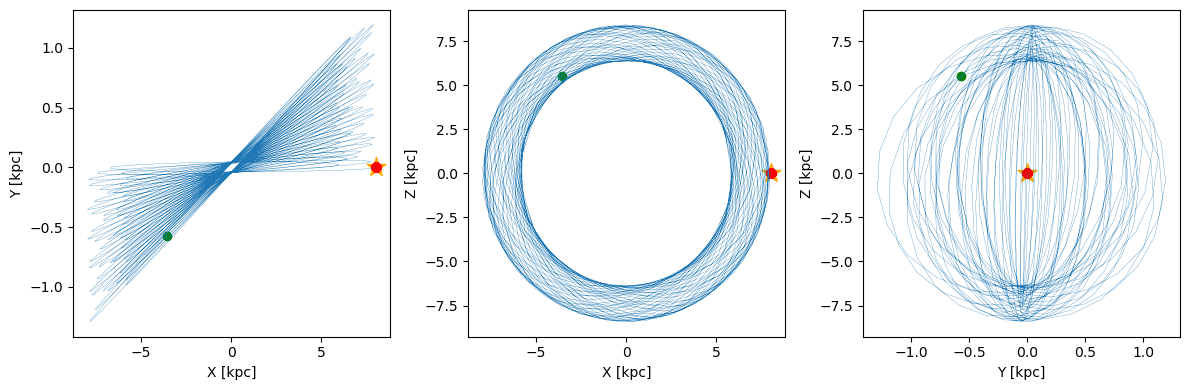

In [13]:
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1],lw=0.2)
ax[0].scatter(mc_end[0],mc_end[1],c='orange',marker='*',s=200)
ax[0].scatter(mc_start[0],mc_start[1],c='green')
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],c='r')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2],lw=0.2)
ax[1].scatter(mc_end[0],mc_end[2],c='orange',marker='*',s=200)
ax[1].scatter(mc_start[0],mc_start[2],c='green')
ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],c='r')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2],lw=0.2)
ax[2].scatter(mc_end[1],mc_end[2],c='orange',marker='*',s=200)
ax[2].scatter(mc_start[1],mc_start[2],c='green')
ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],c='r')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()
plt.show()


ValueError: 'c' argument has 9842 elements, which is inconsistent with 'x' and 'y' with size 10000.

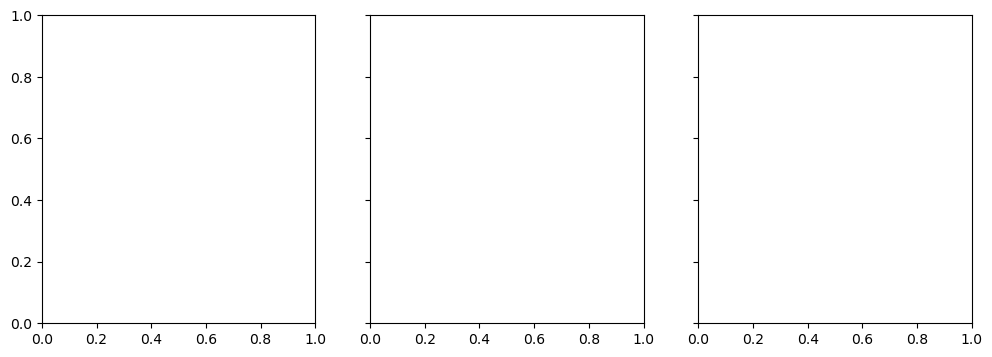

In [14]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=1,sharex=1)
sc=ax[0].scatter(mcp_xc[:,0],mcp_xc[:,1],s=1,c=color,cmap='viridis')

ax[0].scatter(mcp_xc[:,0],mcp_xc[:,1],s=1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xc[:,0],mcp_xc[:,2],s=1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xc[:,1],mcp_xc[:,2],s=1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

x0, x1 = ax[0].get_xlim()
y0, y1 = ax[0].get_ylim()
w = max(x1 - x0, y1 - y0)
xc, yc = (x0 + x1) / 2, (y0 + y1) / 2
ax[0].set_xlim(xc - w/2, xc + w/2)
ax[0].set_ylim(yc - w/2, yc + w/2)
x0, x1 = ax[1].get_xlim()
y0, y1 = ax[1].get_ylim()
w = max(x1 - x0, y1 - y0)
xc, yc = (x0 + x1) / 2, (y0 + y1) / 2
ax[1].set_xlim(xc - w/2, xc + w/2)
ax[1].set_ylim(yc - w/2, yc + w/2)
x0, x1 = ax[2].get_xlim()
y0, y1 = ax[2].get_ylim()
w = max(x1 - x0, y1 - y0)
xc, yc = (x0 + x1) / 2, (y0 + y1) / 2
ax[2].set_xlim(xc - w/2, xc + w/2)
ax[2].set_ylim(yc - w/2, yc + w/2)

fig.colorbar(sc,ax=ax)

#plt.tight_layout()

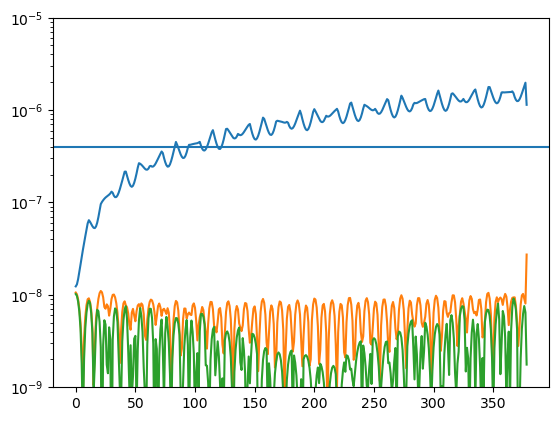

In [15]:
plt.plot(SD)
plt.yscale('log') #vy=1
plt.ylim((1e-9,1e-5))
plt.axhline(y=4e-7)

In [21]:
SD

[array([1.23566227e-08, 1.06062968e-08, 1.02210780e-08]),
 array([1.29844427e-08, 1.01553463e-08, 9.75573057e-09]),
 array([1.47978965e-08, 8.91621170e-09, 8.48558285e-09]),
 array([1.75892550e-08, 7.15561529e-09, 6.61816627e-09]),
 array([2.12147771e-08, 5.06676883e-09, 4.34041135e-09]),
 array([2.55843381e-08, 2.77632081e-09, 1.81333659e-09]),
 array([3.06480263e-08, 8.14935519e-10, 3.79699914e-10]),
 array([3.64073614e-08, 3.39470664e-09, 2.03065153e-09]),
 array([4.29407876e-08, 5.75854660e-09, 4.33900217e-09]),
 array([5.04450185e-08, 7.70239421e-09, 6.38358341e-09]),
 array([5.92844448e-08, 8.95874541e-09, 7.93789757e-09]),
 array([6.43376733e-08, 9.17522638e-09, 8.65454004e-09]),
 array([6.17384885e-08, 8.36027060e-09, 8.15341441e-09]),
 array([5.84653870e-08, 6.86108857e-09, 6.30863058e-09]),
 array([5.53583782e-08, 4.28141805e-09, 3.83454458e-09]),
 array([5.32059193e-08, 1.05329588e-09, 8.67092188e-10]),
 array([5.27994095e-08, 2.70782407e-09, 1.82847431e-09]),
 array([5.4980

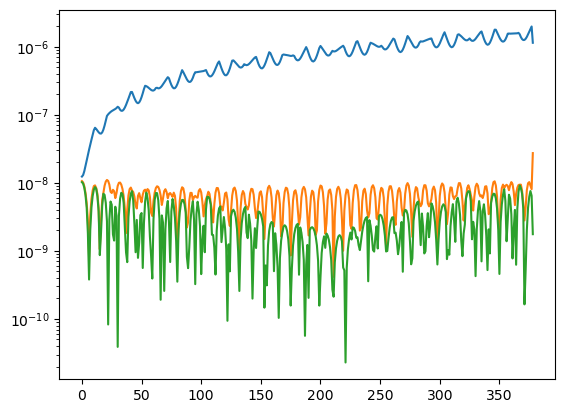

In [ ]:
plt.plot(SD)
plt.yscale('log') #for vy=10

ValueError: x and y must have same first dimension, but have shapes (378,) and (379,)

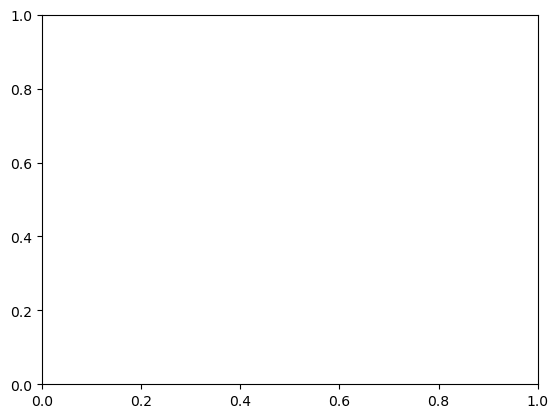

In [17]:
SD_arr = np.array(SD)
plt.plot(SD_t, SD_arr[:,0], label=r'$\sigma_x$')
plt.plot(SD_t, SD_arr[:,1], label=r'$\sigma_y$')
plt.plot(SD_t, SD_arr[:,2], label=r'$\sigma_z$')
plt.xlabel('time')
plt.ylabel(r'$\sigma$ [kpc]')
plt.legend()
plt.yscale('log')

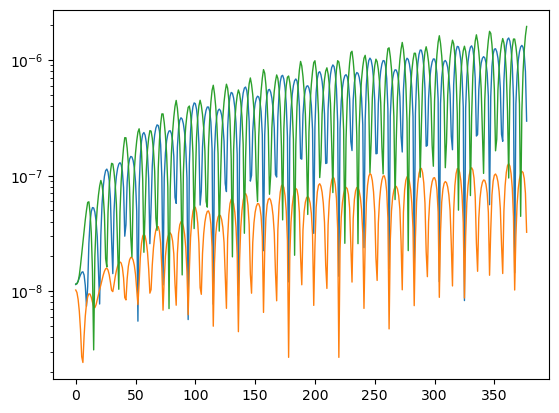

In [19]:
plt.plot(np.array(mean_axis_length),lw=1)
plt.yscale('log')

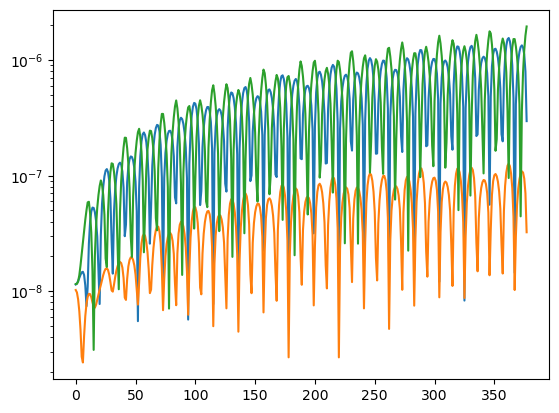

In [20]:
plt.plot(mean_axis_length)
plt.yscale('log')

In [23]:
#check why disoriented streams.

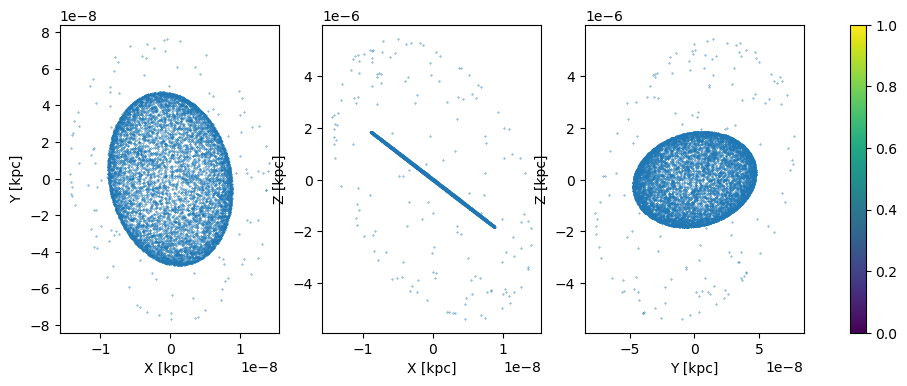

In [22]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
sc=ax[0].scatter(mcp_xc[:,0],mcp_xc[:,1],s=0.1)
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xc[:,0],mcp_xc[:,2],s=0.1)
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xc[:,1],mcp_xc[:,2],s=0.1)
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')
fig.colorbar(sc,ax=ax)


#plt.tight_layout()

In [23]:
pca=PCA(n_components=3)
mcp_xr=pca.fit_transform(mcp_xc)
print('SD along axes:',pca.explained_variance_**0.5)
print('principal axes (rows):\n',pca.components_)

for k in np.unique(color)[:-1]:
    m = color==k
    print(k,len(mcp_xc[m,0]))
    plt.scatter(mcp_xc[m,0], mcp_xc[m,2], s=3, label=int(k))
plt.show()


SD along axes: [9.96102808e-06 7.37408884e-07 4.82847918e-08]
principal axes (rows):
 [[-0.01400194  0.00216961  0.99989961]
 [-0.00117396  0.99999692 -0.00218626]
 [ 0.99990128  0.00120445  0.01399935]]


In [24]:
pca=PCA(n_components=3)
xc=pca.fit_transform(mcp_xv)

ValueError: 'c' argument has 1 elements, which is inconsistent with 'x' and 'y' with size 4432.

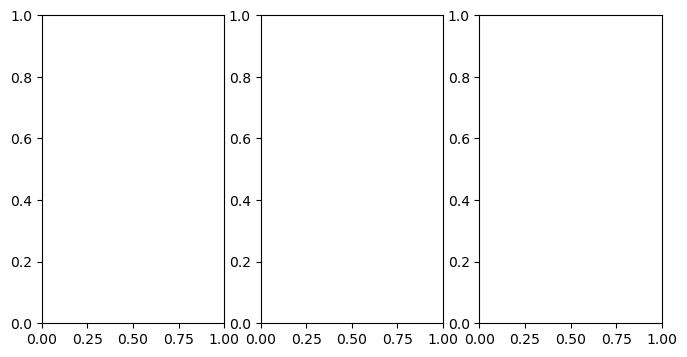

In [25]:
fig,ax=plt.subplots(1,3,figsize=(8,4),sharey=0,sharex=0)
ax[0].scatter(xc[:,0],xc[:,1],s=0.1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(xc[:,0],xc[:,2],s=0.1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(xc[:,1],xc[:,2],s=0.1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')


plt.tight_layout()

In [26]:
pca.explained_variance_

array([9.59179617e-08, 7.03640082e-11, 2.22888019e-12])

In [27]:
sigma=np.sqrt(agama.G*mc.mass/mc.radius)
sigma

np.float64(0.00039641065550990876)

In [29]:
V=np.sqrt(agama.G*pot_mw.enclosedMass(8)/8)
V

np.float64(221.20539296633908)

In [31]:
V*np.sqrt(mc.mass*8/mc.radius/pot_mw.enclosedMass(8))


np.float64(0.00039641065550990876)

In [24]:
F_der=pot_mw.eval(o[:,:3],der=1)


In [25]:
for i in F_der:
    print(i)

[-485.09939761 -886.65765066  603.24494802   65.9566495  -121.80959443
 -761.09794624]
[   42.72171024 -1069.38018063   158.53001101   188.00440372
  -186.00554195 -1130.87216997]
[  912.67181257 -1326.05313448  -965.93757861   385.13024559
  -186.01960883 -1112.42034504]
[  670.07616873 -1190.28974012  -472.71931447   324.7561204
   190.47964342  1123.4582793 ]
[ -36.71982354 -917.90435818  184.93888024  156.35703395  166.44540719
  966.69823655]
[-401.15347341 -753.55777855  485.01336214   64.02783996  115.3311037
  655.07836495]
[-551.34911823 -653.307678    602.32259378   19.42835087   66.08437579
  358.97166378]
[-587.13819724 -594.6410156   624.05583566    1.75309699   24.1415365
  108.68230673]
[-559.43569318 -566.7835316   592.70651061    0.83278048  -11.56325409
 -103.31972006]
[-487.84960789 -565.42718378  524.34610145   11.80536436  -43.42446846
 -291.82062591]
[-370.97770461 -590.65022361  417.55332025   35.28735607  -73.57866822
 -469.57460931]
[-186.46064392 -648.88172442

In [44]:

T = np.array([[F_der[:,0], F_der[:,3], F_der[:,5]],
              [F_der[:,3], F_der[:,1], F_der[:,4]],
              [F_der[:,5], F_der[:,4], F_der[:,2]]]).transpose(2,0,1)   # (N,3,3)

eigvals, eigvecs = np.linalg.eigh(T)   

lam_max  = eigvals[:,-1]          # (N,)
axis_max = eigvecs[:,:,-1]        # (N,3) unit vectors, the stretching direction


In [57]:
axis_max

array([[ 4.56256803e-01,  7.30214244e-02, -8.86847000e-01],
       [ 6.84699165e-01,  1.12619129e-01, -7.20072208e-01],
       [ 8.96570936e-01,  1.49925139e-01, -4.16752935e-01],
       ...,
       [ 7.62517997e-01, -2.14555217e-03, -6.46963446e-01],
       [ 8.82262876e-01, -1.13568824e-03, -4.70755698e-01],
       [ 1.00000000e+00, -6.06601296e-08,  7.34300986e-06]],
      shape=(1000, 3))

176.1869474

In [59]:
np.abs(axis_max) 
np.degrees(np.arccos(cos_xyz))  

array([[6.28541717e+01, 8.58124535e+01, 2.75203222e+01],
       [4.67880472e+01, 8.35336810e+01, 4.39395576e+01],
       [2.62890700e+01, 8.13774117e+01, 6.53702442e+01],
       ...,
       [4.03133154e+01, 8.98770688e+01, 4.96869519e+01],
       [2.80834507e+01, 8.99349298e+01, 6.19166383e+01],
       [4.20738059e-04, 8.99999965e+01, 8.99995793e+01]], shape=(1000, 3))

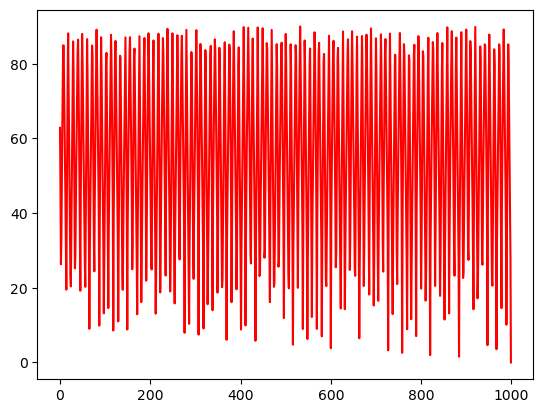

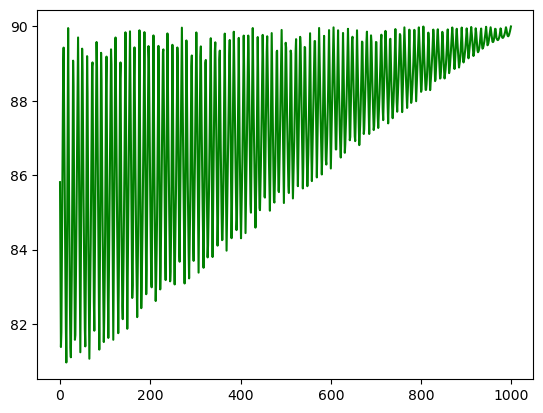

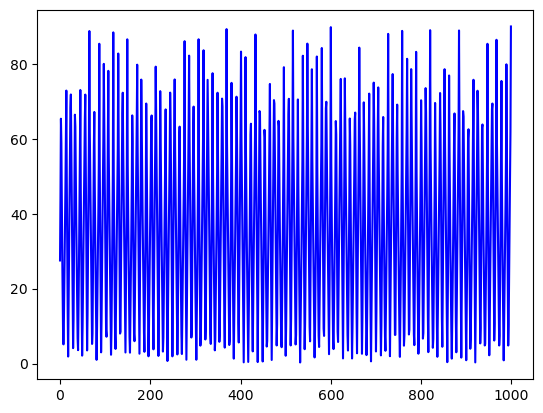

/tmp/ipykernel_3303072/4098540966.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


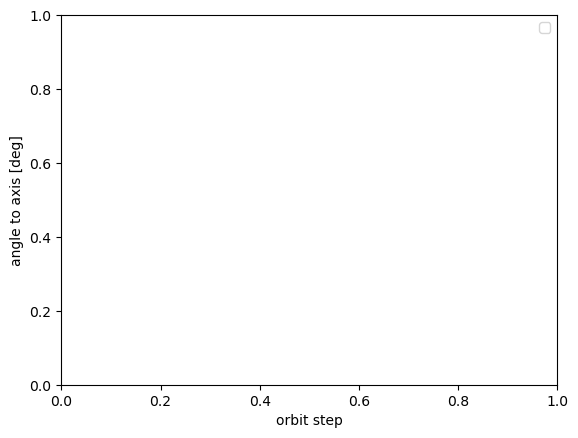

In [55]:
dominant = np.argmax(np.abs(axis_max), axis=1)    # (N,)  0 = x, 1 = y, 2 = z
labels = np.array(['x', 'y', 'z'])[dominant]
cos_xyz = np.abs(axis_max)                          # (N,3), each between 0 and 1
ang_xyz = np.degrees(np.arccos(cos_xyz))            # angle to x, y, z axes in degrees
import matplotlib.pyplot as plt

ang_xyz = np.degrees(np.arccos(np.clip(np.abs(axis_max), 0, 1)))   # (N,3)

plt.plot(ang_xyz[:,0], label='x',c='r')
plt.show()
plt.plot(ang_xyz[:,1], label='y',c='g')
plt.show()
plt.plot(ang_xyz[:,2], label='z',c='b')
plt.show()
plt.xlabel('orbit step')
plt.ylabel('angle to axis [deg]')
plt.legend()
plt.show()


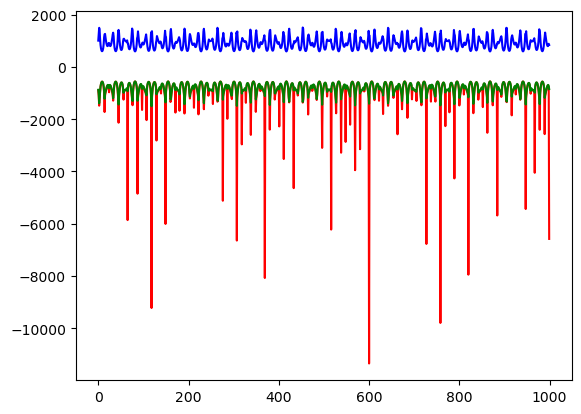

In [49]:
plt.plot(eigvals[:,0],color='r')
plt.plot(eigvals[:,1],color='g')
plt.plot(eigvals[:,2],color='b')

In [37]:
for t in F_der:
    xx, yy, zz, xy, yz, zx = t
    T = np.array([[xx, xy, zx],
                [xy, yy, yz],
                [zx, yz, zz]])
    w, v = np.linalg.eigh(T)
    lam = w[-1]          # largest eigenvalue = stretching
    e = v[:, -1]         # stretching axis

    # angles to x, y, z axes
    angles = np.degrees(np.arccos(np.abs(e)))
    dominant = "xyz"[np.argmax(np.abs(e))]

    print("dominant axis   :", dominant)  
    print(w)

dominant axis   : z
[-897.21365435 -876.13558041 1004.83713451]
dominant axis   : z
[-1100.30309299 -1030.76546744  1262.94010105]
dominant axis   : x
[-1483.0237623  -1390.45484913  1494.15971091]
dominant axis   : x
[-1245.35135759 -1161.09663621  1413.51510794]
dominant axis   : z
[-944.82579984 -898.17322883 1073.31372719]
dominant axis   : z
[-764.83032523 -748.54240044  843.67483584]
dominant axis   : z
[-656.8843125  -653.83247829  708.38258835]
dominant axis   : z
[-596.90038157 -595.03043     634.20743439]
dominant axis   : z
[-568.64943357 -566.87673407  602.01345346]
dominant axis   : z
[-567.18388507 -565.93041638  604.18361124]
dominant axis   : z
[-596.17947628 -589.72924626  641.83411458]
dominant axis   : z
[-661.09865671 -643.29688086  725.46366962]
dominant axis   : x
[-779.83849915 -740.41088066  879.59065562]
dominant axis   : x
[-994.09795238 -937.16351193 1137.53920306]
dominant axis   : x
[-1725.98485597 -1219.58367798  1249.56119988]
dominant axis   : x
[-1098.1

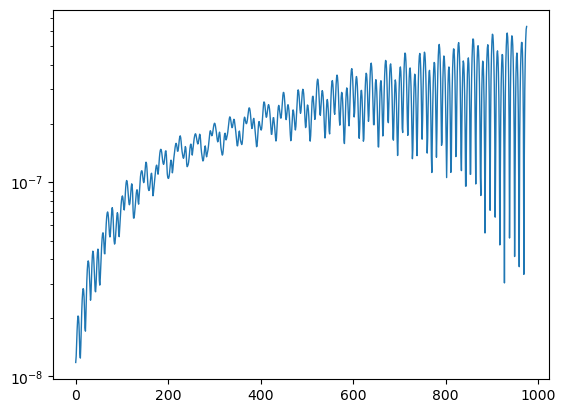

In [37]:
plt.plot(np.array(mean_axis_length)[:,1],lw=1)
plt.yscale('log')

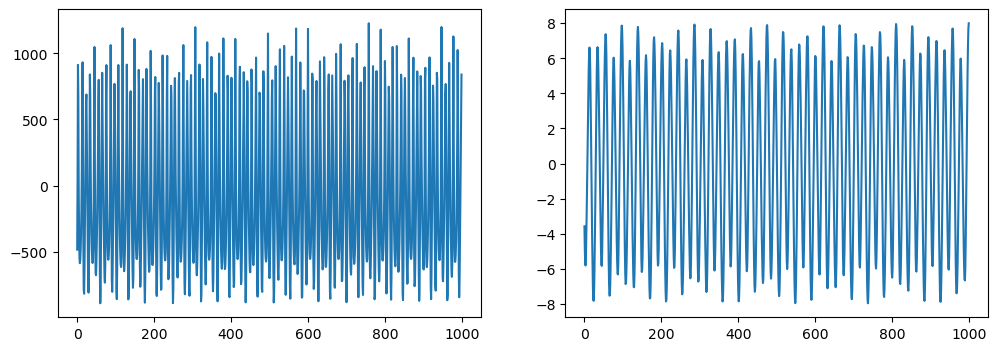

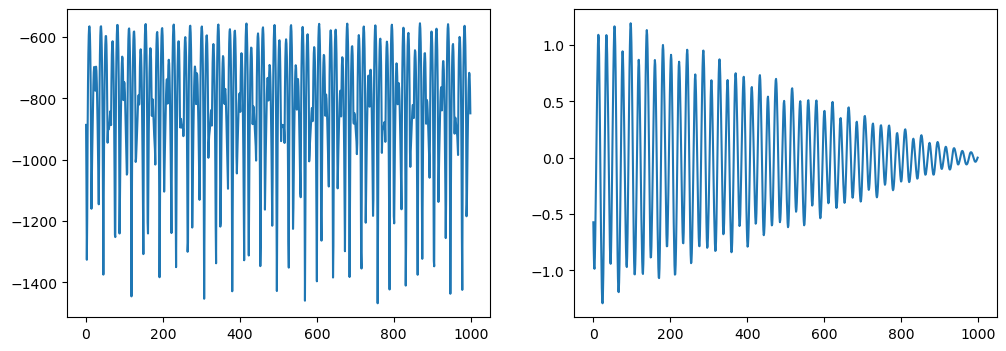

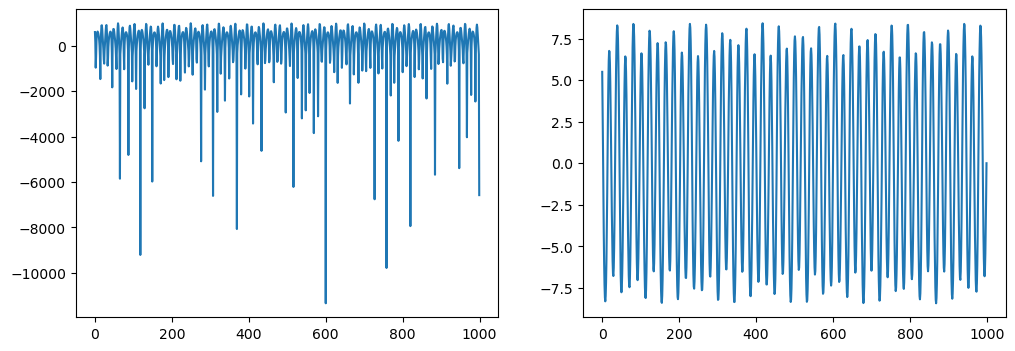

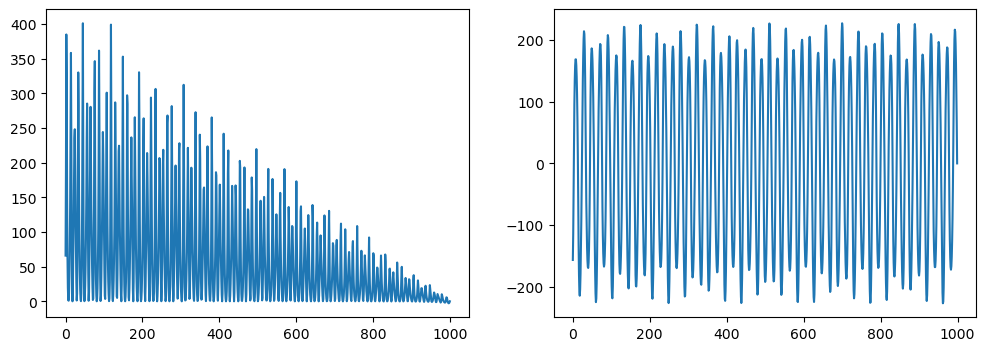

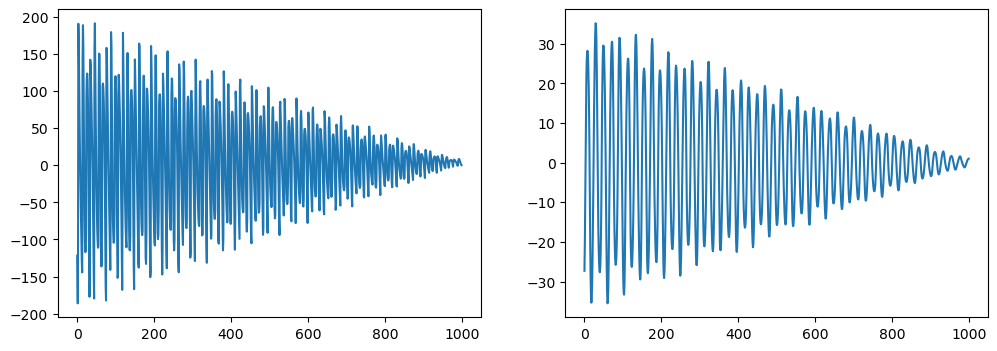

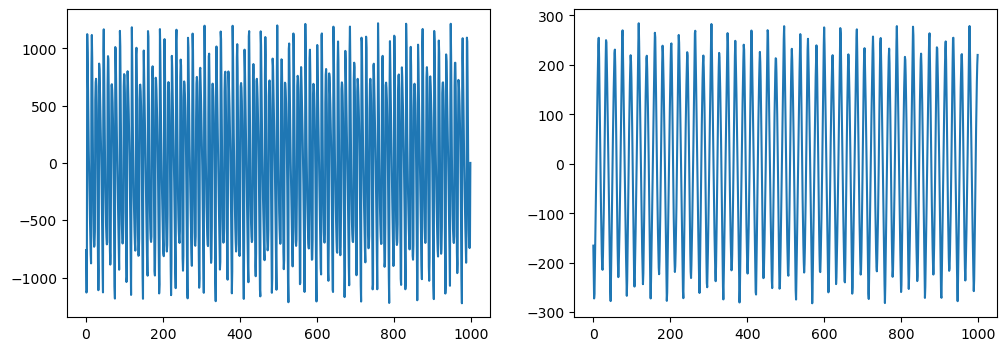

In [42]:
for i in range(6):
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    ax[0].plot(F_der[:,i])
    ax[1].plot(o[:,i])
    plt.show()

In [43]:
s_array=F_der[:,0]*1e-4*r_tidal
s_array.sum()

np.float64(-5.571204671641848e-07)

In [44]:
s_array=F_der[:,1]*1e-4*r_tidal
s_array.sum()

np.float64(-4.505212564863133e-06)

In [45]:
s_array=F_der[:,2]*1e-4*r_tidal
s_array.sum()

np.float64(3.0533267977678107e-07)

In [ ]:
pot_mw.potential(mc_center[:3])

In [ ]:
pot_point = agama.Potential(type='Plummer', mass=pot_mw.enclosedMass(8), scaleRadius=1e-2, center=[0, 0, 0])


In [ ]:
orb2=agama.orbit(ic=mc_center, potential=pot_point, time=simulation_time, timestart=0, dtype=object, accuracy=1e-10, verbose=False)

In [ ]:
t=np.linspace(0,simulation_time,1000)
o=orb2(t)
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1])
ax[0].scatter(final_pos[0],final_pos[1],c='orange',marker='*')
ax[0].scatter(mc_center[0],mc_center[1],c='green')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2])
ax[1].scatter(final_pos[0],final_pos[2],c='orange',marker='*')
ax[1].scatter(mc_center[0],mc_center[2],c='green')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2])
ax[2].scatter(final_pos[1],final_pos[2],c='orange',marker='*')
ax[2].scatter(mc_center[1],mc_center[2],c='green')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [ ]:
F_der=pot_point.eval(o[:,:3],der=1)
for t in F_der:
    xx, yy, zz, xy, yz, zx = t
    T = np.array([[xx, xy, zx],
                [xy, yy, yz],
                [zx, yz, zz]])
    print(T[0][0],T[1][1],T[2][2])

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=1,sharex=1)
ax[0].plot(F_der[:,0],c='r',lw=1)
ax[1].plot(F_der[:,1],c='g',lw=1)
ax[2].plot(F_der[:,2],c='b',lw=1)
ax[0].axhline(y=0)
ax[1].axhline(y=0)
ax[2].axhline(y=0)

In [ ]:
#crossover when \sigma*t takes over 0.5at2
a=-F_der[:,1].mean()*r_tidal*r_tidal
2*sigma/a

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=1,sharex=1)
ax[0].plot(F_der[:,0],c='r',lw=1)
ax[1].plot(F_der[:,1],c='g',lw=1)
ax[2].plot(F_der[:,2],c='b',lw=1)
ax[0].axhline(y=0)
ax[1].axhline(y=0)
ax[2].axhline(y=0)

In [ ]:
mcp_xv_extended = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=5, timestart=0, trajsize=1, accuracy=1e-16,dtype=float,verbose=1)[:, 1])        


In [ ]:
fig,ax=plt.subplots(1,3,figsize=(8,4),sharey=0,sharex=0)
ax[0].scatter(mcp_xv_extended[:,0],mcp_xv_extended[:,1],s=0.1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xv_extended[:,0],mcp_xv_extended[:,2],s=0.1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xv_extended[:,1],mcp_xv_extended[:,2],s=0.1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [ ]:
pca=PCA(n_components=3)
xc_extended=pca.fit_transform(mcp_xv_extended)

NameError: name 'xc_extended' is not defined

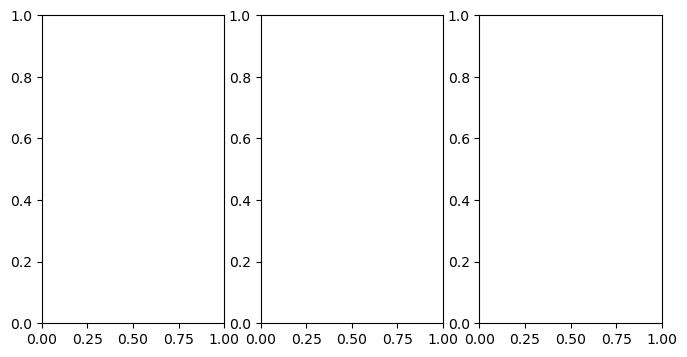

In [68]:
fig,ax=plt.subplots(1,3,figsize=(8,4),sharey=0,sharex=0)
ax[0].scatter(xc_extended[:,0],xc_extended[:,1],s=0.1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(xc_extended[:,0],xc_extended[:,2],s=0.1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(xc_extended[:,1],xc_extended[:,2],s=0.1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')


plt.tight_layout()

In [69]:
np.set_printoptions(suppress=True, precision=2)
pca.explained_variance_ratio_*100

array([99.92,  0.07,  0.  ])

In [ ]:
#so the shear in the x-y axis is what causes the elongation in y, which both have the same nature 

In [40]:

import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
from scipy.stats import uniform_direction

def generate_mc_particles(M,R, N,pmass):
    
    m_array=np.ones(N)*pmass
    pos_unit=uniform_direction(3).rvs(N)  # shape (N, 3)
    coords=R*pos_unit
    vel_unit = uniform_direction(3).rvs(N)  # shape (N, 3)
    v_ideal=np.sqrt(agama.G*M/R)
    vel=v_ideal*vel_unit
    return np.column_stack([coords, vel]), m_array



In [41]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
Nbody_total=1e4
pmass=mc.mass/Nbody_total
print('mass and radius:',mc.mass,mc.radius,pmass)


mass and radius: 3.522249760236229e-14 2.6361671941062195e-12 3.522249760236229e-18


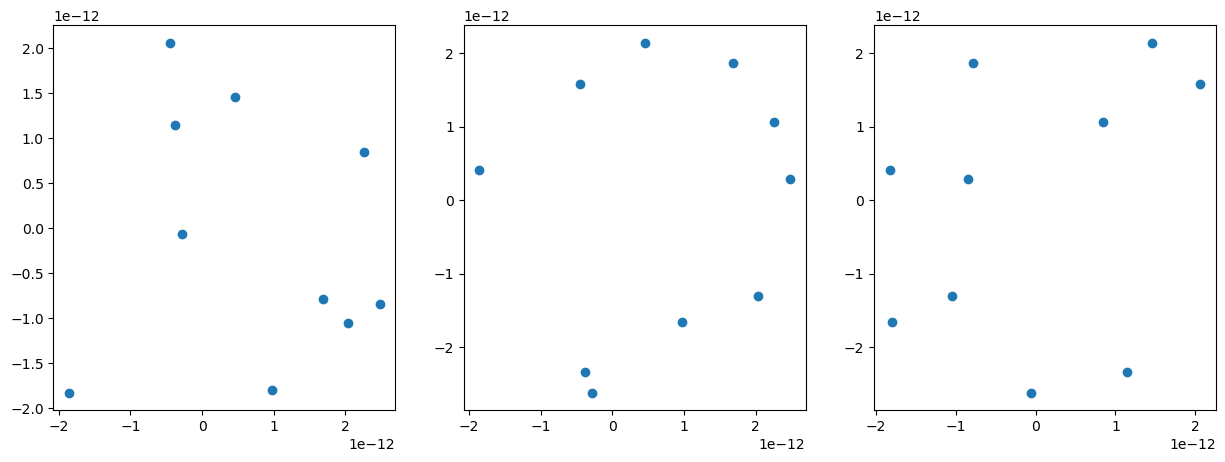

In [42]:
xv=generate_mc_particles(mc.mass,mc.radius,10,pmass)[0]
x=xv[:,:3]
v=xv[:,3:]
fig,ax=plt.subplots(1,3,figsize=(15,5))
ax[0].scatter(x[:,0],x[:,1])
ax[1].scatter(x[:,0],x[:,2])
ax[2].scatter(x[:,1],x[:,2])

[0.00023972 0.00023972 0.00023972 0.00023972 0.00023972 0.00023972
 0.00023972 0.00023972 0.00023972 0.00023972]


ValueError: Too many bins for data range. Cannot create 10 finite-sized bins.

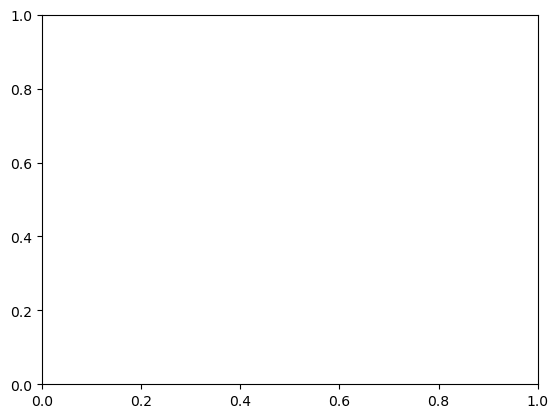

In [45]:
speed=np.linalg.norm(v,axis=1)
print(speed)
plt.hist(speed)

In [ ]:
mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)
N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center)
N_encounter_with_star_array.append(N_encounter_with_star)
col_time=tupd/N_encounter_with_star
its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)


array([0.00023972, 0.00023972, 0.00023972, 0.00023972, 0.00023972,
       0.00023972, 0.00023972, 0.00023972, 0.00023972, 0.00023972])

In [ ]:
color_index=0
SD_count=0

while time_i < simulation_time-0.5*tupd:

    mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)
    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center)
    N_encounter_with_star_array.append(N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
    delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
    
    

    Eb=binding_energy(mc_mass,mc_rvir)
    Ei=total_energy(Eb)

    delEbyE=abs(delE/Eb)
    mass_loss=mc_mass*get_dm_frac(delEbyE)

    Ef=Ei+(1-get_fej(delEbyE))*delE-get_fub(delEbyE)*Ei
    
    Ef_array.append(Ef)
    Ei_array.append(Ei)
    E2_array.append((1-get_fej(delEbyE))*delE)
    E3_array.append(get_fub(delEbyE)*Ei)
    
    mc_mass_old=mc_mass
    mc_mass=mc_mass-mass_loss
    mc_rvir=((kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef) if Ef<0 else 0

    mass_array.append(mc_mass)
    radius_array.append(mc_rvir)
    mc_array.append(mc_orbit_center)
    mc_time.append(mc_time_center[-1])

    #r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass_old)
    r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass)


    pnum=round(mass_loss*Nbody_total/mc.mass)
    pnum_array.append(pnum)
    if mc_rvir==0:
        print('dead')
        pnum=round(mc_mass_old*Nbody_total/mc.mass)
        mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass_old,r_tidal,pnum,pmass)
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        mcp_xv_temp+=mc_center
        mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
        mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=simulation_time-time_i, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=1)[:, 1])        
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)
        SD.append(pca.explained_variance_**0.5)
        alive=0
        break    
        
    if mcp_xv.size>0:
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
    
    mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
    mcp_xv_temp+=mc_orbit_center[-1]  
    mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
    mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
    
    """if pnum>0 and color_index!=0:
        print('color_index:',color_index,'first')
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        color_index+=1
        print('time:',time_i,'pnum:',pnum,'mass:',mc_mass,'radius:',mc_rvir)
        fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
        ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.8,c=color,cmap='viridis')
        ax[0].scatter(mcp_xv_temp[:,0],mcp_xv_temp[:,1],s=2,c='orange') 
        ax[0].set_xlabel('X [kpc]')
        ax[0].set_ylabel('Y [kpc]')

        ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
        ax[1].scatter(mcp_xv_temp[:,0],mcp_xv_temp[:,2],s=2,c='orange')
        ax[1].set_xlabel('X [kpc]')
        ax[1].set_ylabel('Z [kpc]')

        ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
        ax[2].scatter(mcp_xv_temp[:,1],mcp_xv_temp[:,2],s=2,c='orange')
        ax[2].set_xlabel('Y [kpc]')
        ax[2].set_ylabel('Z [kpc]')
        ax[2].set
        plt.show()
        plt.tight_layout()    
    elif pnum>0 and color_index==0:
        print('color_index:',color_index,'second')
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)[1:]*color_index])
        color_index+=1
    plt.plot(mcp_xv[:,0], mcp_xv[:,1], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,0], mcp_xv_temp[:,1], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][0], mc_orbit_center[-1][1], 's', markersize=5, color='red')
    plt.show()
    plt.plot(mcp_xv[:,0], mcp_xv[:,2], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,0], mcp_xv_temp[:,2], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][0], mc_orbit_center[-1][2], 's', markersize=5, color='red')
    plt.show()
    plt.plot(mcp_xv[:,1], mcp_xv[:,2], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,1], mcp_xv_temp[:,2], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][1], mc_orbit_center[-1][2], 's', markersize=5, color='red')
    plt.show()
    """

    if mcp_xv.size>1 and SD_count%1==0 and time_i>0:
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)
        SD.append(pca.explained_variance_**0.5)
        SD_t.append(time_i) 

        #pos=np.std(pos, axis=0)
        mean_axis_length.append(np.std(mcp_xv[:,:3],axis=0))

    mc_center = mc_orbit_center[-1]
    time_i += tupd
    


    SD_count+=1
    print(time_i,pnum)
#color=np.array(color[1:])
"""fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.8,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')
plt.tight_layout()"""